# robust-crew: results

Reads only the generated files in `reports/` (run `python -m robust_crew.pipeline` first). Nothing is recomputed here.

In [1]:
import json, pathlib
import pandas as pd
from IPython.display import Image, Markdown, display
R = pathlib.Path('..') / 'reports'
load = lambda f: json.loads((R / f).read_text())

## 1. Data: AA at CLT, 2022-2023

In [2]:
q = load('phase1_summary.json')
pd.DataFrame(q['daily_hub_departures'])

,split,days,mean,min,max,cancelled_pct
0,train,485,295.2,147,346,2.22
1,calib,61,328.0,271,345,0.45
2,test_summer,62,331.7,243,344,2.03
3,gap,61,325.4,233,352,0.33
4,test_winter,61,318.0,131,389,0.03


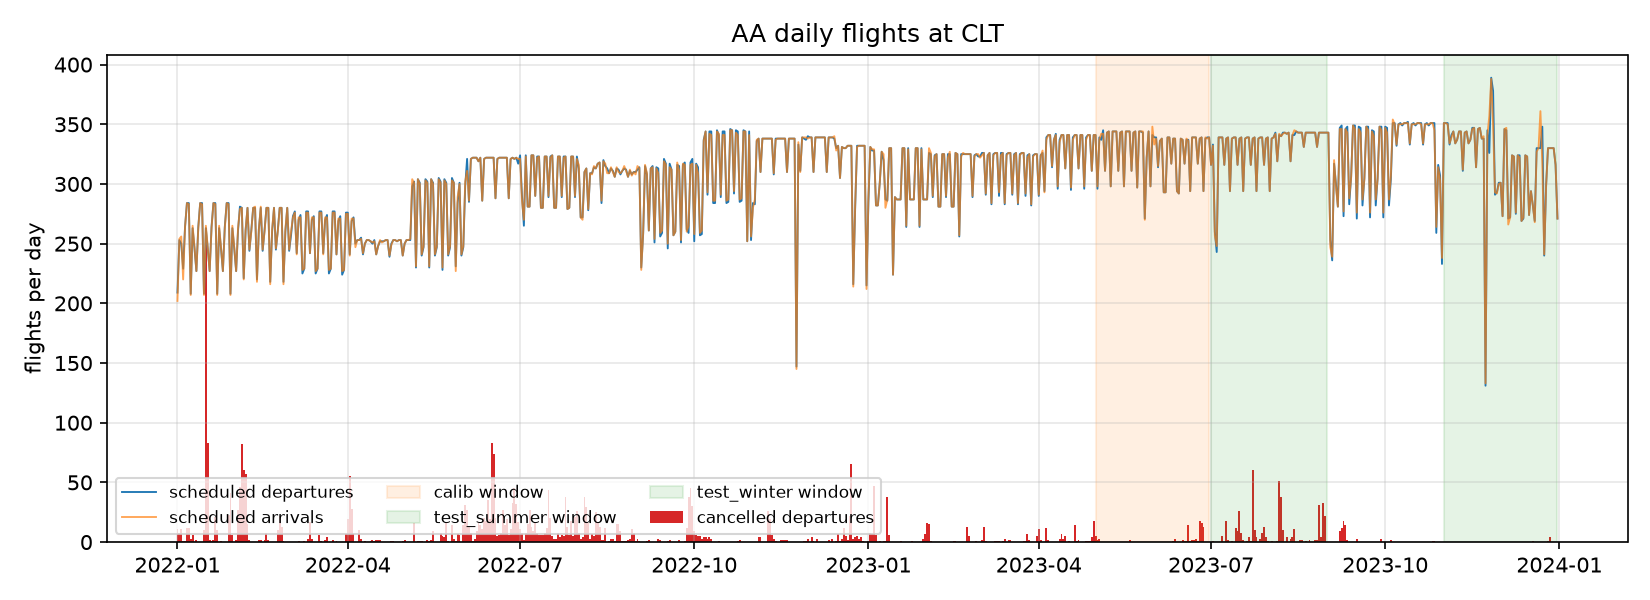

,split,flights,cancelled_pct,diverted_pct,mean_dep_delay_min,arr_del15_pct
0,train,286383,2.25,0.193,13.8,21.9
1,calib,40015,0.50,0.272,20.1,24.7
2,test_summer,41134,2.06,0.292,28.9,30.8
3,gap,39703,0.34,0.154,11.8,18.2
4,test_winter,38788,0.04,0.134,10.1,16.7


In [3]:
display(Image(R / 'figures' / 'daily_hub_flights.png'))
pd.DataFrame(q['outcomes_by_split'])

## 2. Pairings (the CSP)

In [4]:
p = load('phase3_pairings.json')
pd.DataFrame(p['by_split']).T[['days','mean_legs','mean_pairings','mean_legs_plannable','mean_plannable_share','mean_enumerate_seconds','days_capped','days_not_optimal']]

,days,mean_legs,mean_pairings,mean_legs_plannable,mean_plannable_share,mean_enumerate_seconds,days_capped,days_not_optimal
train,485.0,590.480,2261.186,322.598,0.542,0.018,0.0,0.0
calib,61.0,655.984,3042.656,373.902,0.569,0.021,0.0,0.0
test_summer,62.0,663.452,2625.887,377.903,0.568,0.021,0.0,0.0
gap,61.0,650.869,2820.984,365.279,0.557,0.021,0.0,0.0
test_winter,61.0,635.869,2261.672,350.852,0.545,0.019,0.0,0.0


In [5]:
pd.Series(p['dropped_leg_reasons_total'], name='legs dropped (all days)')

arrives at base but no legal feeder from base (crew would have overnighted at spoke)        82956
departs base but no legal connecting return (e.g. evening departure, overnight at spoke)    81998
every route through this leg breaks the duty, block or leg limits                           25899
in some legal pairing, but no exact cover of the day can include it                          8788
Name: legs dropped (all days), dtype: int64

## 3. Connection-break model

In [6]:
m = load('phase4_delay_model.json')
rows = []
for split, d in m['metrics'].items():
    for name, v in d.items():
        rows.append({'split': split, 'model': name, 'auc': v['auc'], 'brier': v['brier'], 'base_rate': v['base_rate'], 'mean_pred': v['mean_pred']})
for split, v in m.get('metrics_planning_without_tail_features', {}).items():
    rows.append({'split': split, 'model': 'planning_without_tail_features', 'auc': v['auc'], 'brier': v['brier'], 'base_rate': v['base_rate'], 'mean_pred': v['mean_pred']})
pd.DataFrame(rows).pivot(index='model', columns='split', values='auc')

split,calib,test_summer,test_winter
model,,,
baseline_route_history,0.7436,0.7203,0.7506
baseline_slack_logistic,0.7452,0.7206,0.7557
operations_model,0.7858,0.7693,0.7966
planning_model,0.7777,0.7622,0.7885
planning_model_uncalibrated,0.7770,0.7626,0.7889
planning_without_tail_features,0.7538,0.7433,0.7579


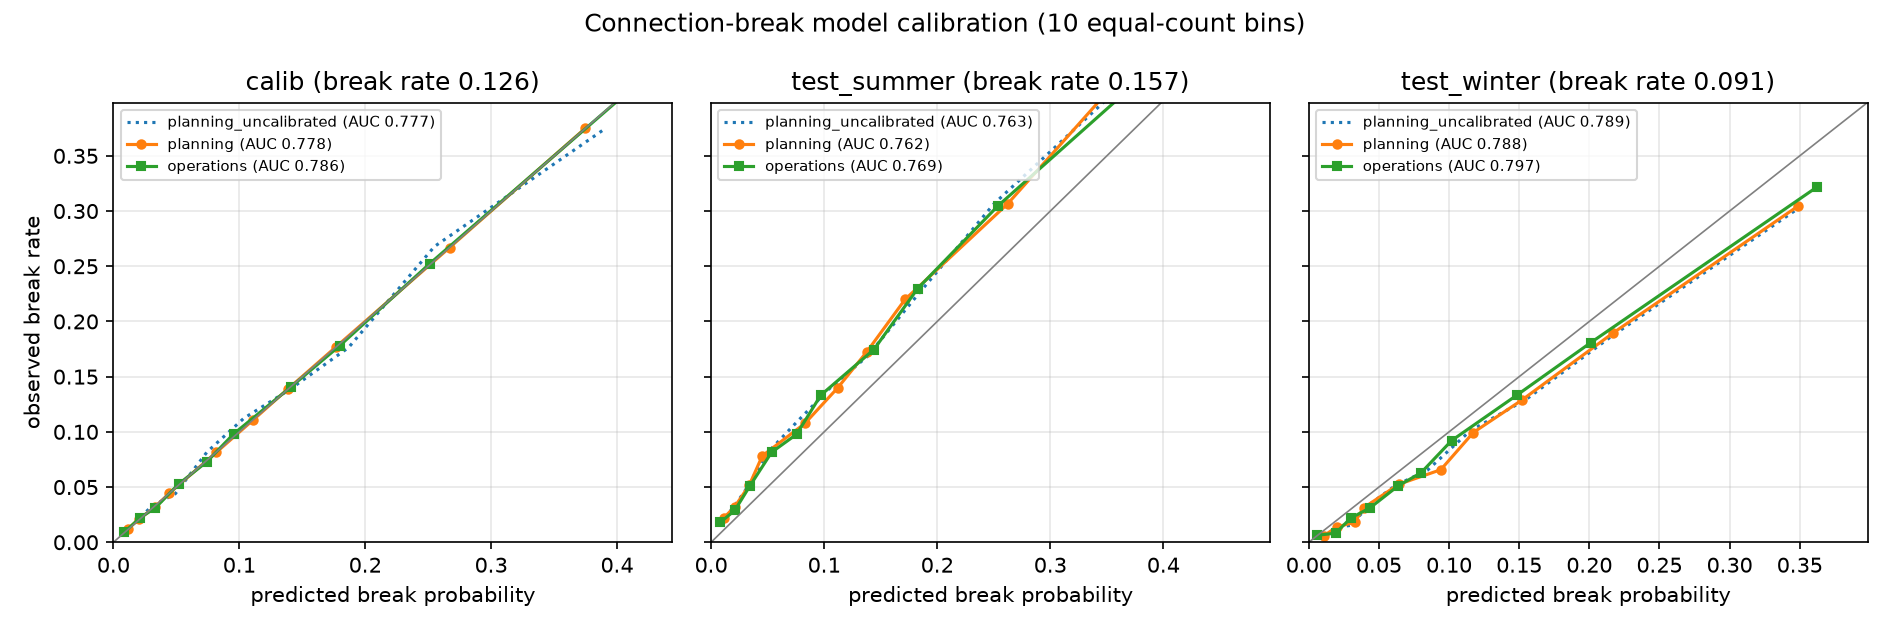

In [7]:
display(Image(R / 'figures' / 'break_model_calibration.png'))

## 4. Planners

In [8]:
o = load('phase5_planners.json')
pd.DataFrame(o['summary']['test_summer'])[['planner','param','days_feasible','mean_crews','mean_cost','mean_exp_breaks','mean_exempt_legs','max_gap']]

,planner,param,days_feasible,mean_crews,mean_cost,mean_exp_breaks,mean_exempt_legs,max_gap
0,baseline,NaN,62,111.35,1176.93,49.378,0.00,0.0
1,soft,0.50,62,111.35,1177.13,45.266,0.00,0.0
2,soft,1.00,62,111.35,1177.54,45.047,0.00,0.0
3,soft,2.00,62,111.47,1179.13,44.651,0.00,0.0
4,soft,4.00,62,115.26,1198.79,42.286,0.00,0.0
5,soft,8.00,62,122.89,1243.04,39.781,0.00,0.0
6,soft,16.00,62,136.47,1326.89,37.739,0.00,0.0
7,soft,32.00,62,166.08,1542.19,36.255,0.00,0.0
8,soft,64.00,62,187.02,1720.09,35.731,0.00,0.0
9,hard,0.50,32,111.66,1179.16,48.458,13.32,0.0


## 5. Replay and repair: the trade-off

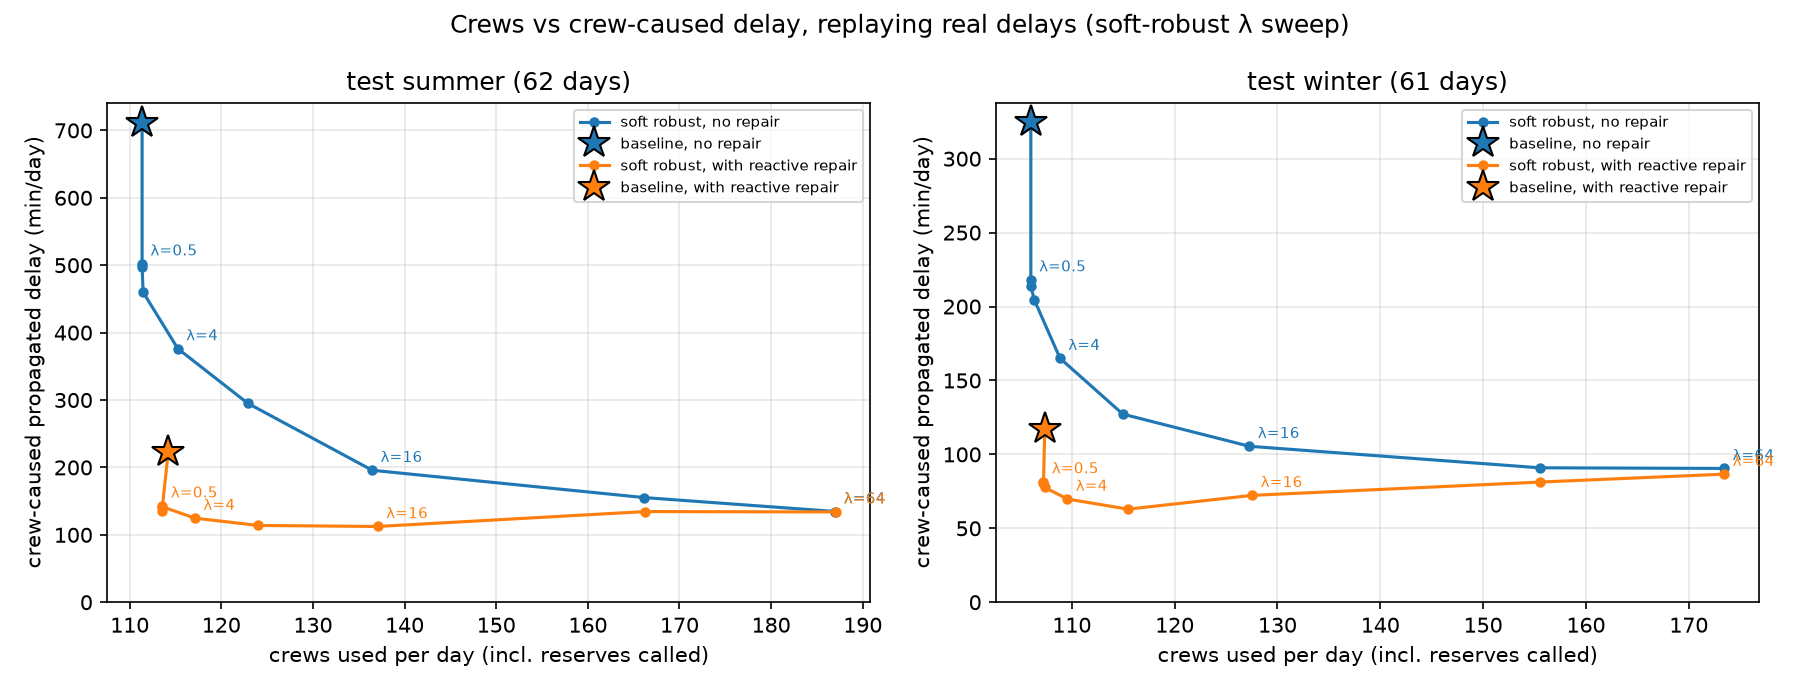

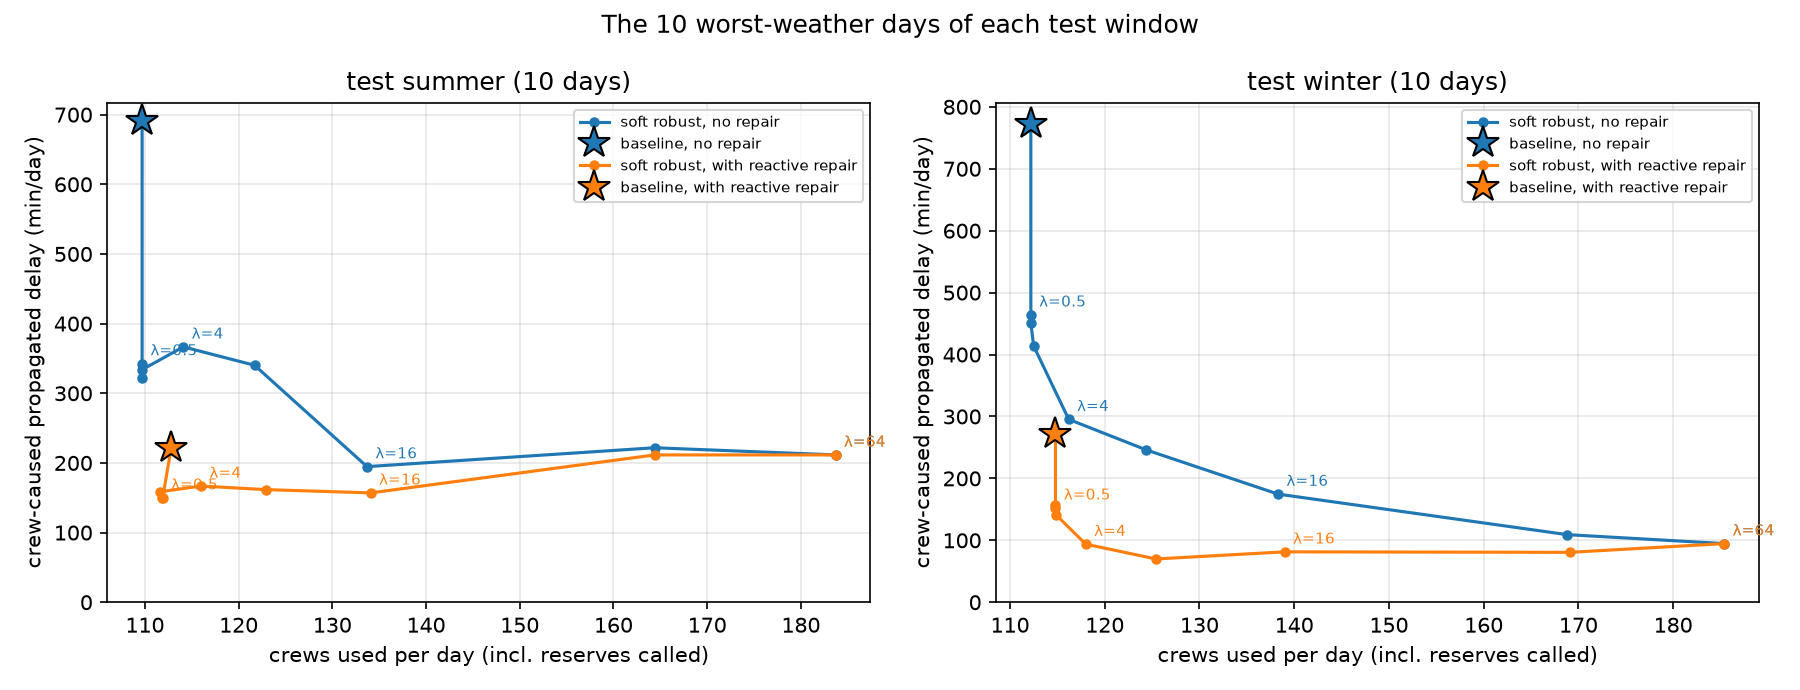

In [9]:
display(Image(R / 'figures' / 'tradeoff.png'))
display(Image(R / 'figures' / 'worst_days.png'))

In [10]:
display(Markdown((R / 'results.md').read_text()))

- **test summer** (62 days): with no repair, the selected soft-robust plan cuts crew-caused delay from 711 to 376 min/day (-47%; paired Δ -335 [-411, -264]) and broken connections from 44.2 to 35.2 for +3.9 crews/day. Reactive repair alone takes the baseline to 223 min/day; robust planning plus repair reaches 125 (paired Δ vs repair alone -99 [-151, -55] min/day).
- **test winter** (61 days): with no repair, the selected soft-robust plan cuts crew-caused delay from 325 to 165 min/day (-49%; paired Δ -160 [-243, -97]) and broken connections from 26.1 to 19.3 for +2.8 crews/day. Reactive repair alone takes the baseline to 117 min/day; robust planning plus repair reaches 70 (paired Δ vs repair alone -48 [-76, -25] min/day).

- **Operations features barely help.** The morning-of model's AUC gain over the planning model: test summer +0.007, test winter +0.008.
- **Morning re-solve (test summer)**, the one repair step that uses operations probabilities: Δ crew-caused delay vs no re-solve -203.8 [-277.6, -136.9] min/day on the baseline plan and +8.1 [-31.9, +48.6] on the selected soft plan (each without reactive repair). Reactive repair, which drives the headline effect, does not use the model's probabilities.
- **Morning re-solve (test winter)**, the one repair step that uses operations probabilities: Δ crew-caused delay vs no re-solve -79.5 [-112.7, -50.1] min/day on the baseline plan and +7.8 [-2.1, +19.0] on the selected soft plan (each without reactive repair). Reactive repair, which drives the headline effect, does not use the model's probabilities.
- **Excluding Thanksgiving (test winter, 60 days):** soft vs baseline Δ delay -162.6 [-246.5, -99.8]; soft + repair vs baseline + repair -48.4 [-78.1, -25.4] min/day.
- **Baseline tie-breaking (test summer):** re-solving the baseline with 5 different choices among cost-tied optima gives mean crew-caused delay between 697 and 735 min/day (largest cost difference 0.00 pay hours, i.e. equally cheap). The selected soft plan's 376 beats every one of them, so its gain is more than lucky tie-breaking; but part of the cheap low-λ gain is simply choosing well among schedules that cost the same.
- **Baseline tie-breaking (test winter):** re-solving the baseline with 5 different choices among cost-tied optima gives mean crew-caused delay between 304 and 336 min/day (largest cost difference 0.02 pay hours, i.e. equally cheap). The selected soft plan's 165 beats every one of them, so its gain is more than lucky tie-breaking; but part of the cheap low-λ gain is simply choosing well among schedules that cost the same.

![Trade-off curve](reports/figures/tradeoff.png)

![Worst-weather days](reports/figures/worst_days.png)

<details><summary>Full tables with confidence intervals</summary>

Selected on CALIB days: soft λ = 4 (largest delay reduction with cost ≤ +2%); hard θ = 0.5.

Means per day with 95% bootstrap intervals over days in brackets; (Δ ...) is the paired difference vs the no-repair baseline on the same days, with its 95% interval. Hard robust is evaluated only on days it was feasible (its mean is over those days). Repair = reactive repair (idle-crew swaps + up to 4 reserves); reserves called count as crews used, but the cost column excludes reserve pay (reserves are on standby payroll either way). Intervals over very few days are unreliable.

**All test days, test summer**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 111.3 [109.9, 112.7] | 115.3 (+3.9 [+3.5, +4.3]) | 111.7 (+0.2 [+0.0, +0.3]) | 114.2 (+2.9 [+2.6, +3.1]) | 117.1 (+5.8 [+5.2, +6.3]) |
| Cost (pay hours) | 1176.9 [1155.7, 1195.5] | 1198.8 (+21.9 [+19.9, +23.9]) | 1179.2 (+0.8 [+0.2, +1.6]) | 1176.9 (+0.0 [+0.0, +0.0]) | 1198.8 (+21.9 [+19.9, +23.8]) |
| Crew-caused delay (min) | 711.4 [594.6, 837.7] | 376.2 (-335.3 [-410.6, -264.0]) | 602.3 (-35.5 [-111.9, +29.8]) | 223.2 (-488.2 [-569.6, -410.2]) | 124.7 (-586.7 [-689.4, -489.1]) |
| Broken crew connections | 44.2 [39.9, 48.8] | 35.2 (-8.9 [-10.0, -7.9]) | 41.7 (+0.7 [-0.2, +1.5]) | 37.9 (-6.3 [-7.1, -5.6]) | 31.7 (-12.5 [-13.8, -11.2]) |
| Crews replaced at duty limit | 10.4 [9.1, 11.8] | 10.7 (+0.2 [-0.3, +0.7]) | 9.8 (-0.0 [-0.5, +0.4]) | 9.3 (-1.1 [-1.3, -0.9]) | 9.6 (-0.8 [-1.3, -0.3]) |
| Duty overruns in the air | 2.5 [1.8, 3.2] | 2.4 (-0.1 [-0.6, +0.3]) | 1.9 (-0.4 [-0.9, +0.0]) | 2.2 (-0.2 [-0.4, -0.1]) | 2.3 (-0.1 [-0.6, +0.3]) |

Days: 62; hard feasible on 32 (52%).

**All test days, test winter**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 106.0 [101.4, 109.9] | 108.8 (+2.8 [+2.3, +3.4]) | 105.7 (+0.1 [+0.0, +0.2]) | 107.4 (+1.4 [+1.0, +1.7]) | 109.6 (+3.6 [+3.0, +4.2]) |
| Cost (pay hours) | 1136.6 [1087.0, 1179.7] | 1152.5 (+15.9 [+13.4, +18.5]) | 1120.3 (+0.5 [+0.0, +1.1]) | 1136.6 (+0.0 [+0.0, +0.0]) | 1152.5 (+15.9 [+13.4, +18.5]) |
| Crew-caused delay (min) | 324.9 [244.4, 418.8] | 165.0 (-159.9 [-243.2, -97.3]) | 255.3 (-13.7 [-50.7, +17.3]) | 117.4 (-207.5 [-281.7, -145.5]) | 69.8 (-255.1 [-342.9, -180.9]) |
| Broken crew connections | 26.1 [22.9, 29.4] | 19.3 (-6.8 [-8.0, -5.6]) | 21.0 (+0.3 [-0.1, +0.9]) | 22.9 (-3.2 [-3.9, -2.5]) | 17.7 (-8.4 [-9.8, -7.0]) |
| Crews replaced at duty limit | 4.2 [3.4, 5.2] | 4.9 (+0.6 [+0.2, +1.1]) | 3.4 (-0.1 [-0.4, +0.1]) | 3.7 (-0.6 [-0.8, -0.3]) | 4.5 (+0.3 [-0.1, +0.7]) |
| Duty overruns in the air | 1.3 [0.9, 1.8] | 1.5 (+0.1 [-0.1, +0.4]) | 0.9 (+0.0 [-0.1, +0.2]) | 1.3 (-0.0 [-0.1, +0.0]) | 1.4 (+0.1 [-0.2, +0.4]) |

Days: 61; hard feasible on 27 (44%).

**10 worst-weather days, test summer**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 109.7 [106.9, 112.2] | 114.1 (+4.4 [+3.7, +5.2]) | 110.7 (+0.3 [+0.0, +1.0]) | 112.8 (+3.1 [+2.6, +3.6]) | 116.0 (+6.3 [+5.1, +7.6]) |
| Cost (pay hours) | 1160.3 [1128.1, 1191.6] | 1184.5 (+24.1 [+20.2, +28.5]) | 1177.9 (+1.9 [+0.0, +4.9]) | 1160.3 (+0.0 [+0.0, +0.0]) | 1184.5 (+24.1 [+20.2, +28.4]) |
| Crew-caused delay (min) | 690.4 [501.6, 906.9] | 366.6 (-323.8 [-437.9, -214.7]) | 684.0 (+66.0 [-80.0, +168.0]) | 221.5 (-468.9 [-622.5, -331.6]) | 166.8 (-523.6 [-705.6, -357.1]) |
| Broken crew connections | 61.8 [51.5, 74.8] | 52.5 (-9.3 [-12.1, -6.9]) | 72.0 (+2.0 [-2.0, +5.0]) | 55.7 (-6.1 [-7.5, -4.8]) | 49.1 (-12.7 [-16.3, -9.8]) |
| Crews replaced at duty limit | 15.9 [12.1, 20.2] | 16.1 (+0.2 [-1.0, +1.3]) | 15.7 (-1.7 [-3.0, -1.0]) | 14.7 (-1.2 [-1.6, -0.7]) | 14.6 (-1.3 [-2.4, +0.0]) |
| Duty overruns in the air | 5.2 [3.0, 7.7] | 6.0 (+0.8 [-0.5, +2.2]) | 3.7 (+0.0 [-2.0, +2.0]) | 4.8 (-0.4 [-0.8, +0.0]) | 6.0 (+0.8 [-0.6, +2.2]) |

Days: 10; hard feasible on 3 (30%).

**10 worst-weather days, test winter**

| Metric | Baseline | Best soft (Δ) | Best hard, paired days (Δ) | Baseline + repair (Δ) | Best soft + repair (Δ) |
|---|---|---|---|---|---|
| Crews used | 112.2 [104.0, 123.2] | 116.2 (+4.0 [+2.7, +5.3]) | 138.0 (+0.0 [+0.0, +0.0]) | 114.8 (+2.6 [+1.5, +3.6]) | 118.0 (+5.8 [+4.1, +7.3]) |
| Cost (pay hours) | 1212.1 [1128.5, 1319.7] | 1234.3 (+22.2 [+15.1, +29.5]) | 1454.3 (+0.4 [+0.0, +0.8]) | 1212.1 (+0.0 [+0.0, +0.0]) | 1234.3 (+22.2 [+15.0, +29.4]) |
| Crew-caused delay (min) | 771.9 [433.3, 1153.6] | 295.3 (-476.6 [-881.5, -156.5]) | 537.0 (-108.5 [-316.0, +99.0]) | 271.7 (-500.2 [-801.0, -235.8]) | 93.8 (-678.1 [-1038.9, -367.2]) |
| Broken crew connections | 44.5 [33.9, 54.0] | 33.1 (-11.4 [-15.8, -6.7]) | 32.5 (+1.0 [-3.0, +5.0]) | 39.1 (-5.4 [-7.5, -3.1]) | 29.7 (-14.8 [-19.7, -9.7]) |
| Crews replaced at duty limit | 8.5 [5.2, 12.5] | 9.7 (+1.2 [+0.1, +2.4]) | 9.0 (-1.0 [-2.0, +0.0]) | 7.2 (-1.3 [-2.3, -0.4]) | 8.4 (-0.1 [-1.3, +1.3]) |
| Duty overruns in the air | 3.2 [1.5, 5.2] | 3.1 (-0.1 [-1.0, +0.6]) | 4.0 (-0.5 [-1.0, +0.0]) | 3.1 (-0.1 [-0.3, +0.0]) | 3.0 (-0.2 [-1.0, +0.5]) |

Days: 10; hard feasible on 2 (20%).

</details>

**Does robust planning add anything once repair exists?** Best soft + repair minus baseline + repair, paired by day (crew-caused delay, min/day; broken connections/day):

| Window | Days | Δ delay | Δ broken connections | Δ crews used |
|---|---|---|---|---|
| test summer | 62 | -98.5 [-151.4, -54.7] | -6.2 [-7.0, -5.3] | +2.9 [+2.5, +3.4] |
| test winter | 61 | -47.6 [-76.3, -25.1] | -5.2 [-6.2, -4.2] | +2.2 [+1.7, +2.7] |
| test summer (worst-weather days) | 10 | -54.7 [-135.7, +12.7] | -6.6 [-9.7, -3.9] | +3.2 [+1.9, +4.5] |
| test winter (worst-weather days) | 10 | -177.9 [-314.1, -67.6] | -9.4 [-13.0, -5.9] | +3.2 [+2.1, +4.3] |


In [11]:
s = load('phase6_replay.json')
pd.Series(s['simulator_validation'])

flights                                                                  474835
mean_actual_arr_delay                                                     13.84
mean_sim_arr_delay_no_crew                                                 8.84
mae_sim_vs_actual                                                         11.17
corr_sim_vs_actual                                                       0.8271
note                          No-crew replay vs real arrival delays; real de...
dtype: object